## 1. Setup & configuration

In [ ]:
import os, sys, glob, json, math, time, random, copy, warnings, subprocess
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import roi_align
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, precision_score, recall_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
cv2.setNumThreads(1)                      # we parallelise over images instead

# Optional HF token (timm pulls weights from the HF hub). Works without it too.
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    print("HF_TOKEN secret not found - continuing without it.")

# ------------------------------- CONFIG ---------------------------------------------------
GPU_ID        = 0
SEEDS         = [42]            
SPLIT_SEED    = 42              # fixed so every seed trains/evaluates on the same split
BACKBONE      = "swin_base_patch4_window7_224"   # try "swin_small_patch4_window7_224" / "swin_tiny_..." for speed
SIZE          = 448             # cached image resolution; patches are cropped from this
GLOBAL_RES    = 224             # Swin input (downsampled from SIZE)
NUM_PATCHES   = 4
PATCH_FRAC    = 0.30            # patch side = 30 % of image side (134 px at 448)
PATCH_OUT     = 160             # patches are resampled to this size for EfficientNet
BATCH         = 16              # raise to 24-32 with swin_small/tiny; lower to 12 if you hit OOM
EPOCHS        = 20
PATIENCE      = 8
LR_GLOBAL, LR_LOCAL, LR_HEAD = 2e-5, 1e-4, 5e-4
WEIGHT_DECAY  = 1e-2
EMA_DECAY     = 0.998
AUX_WEIGHT    = 0.4             # weight of auxiliary global-head loss
NUM_WORKERS   = 2               # data is cached, so workers are cheap
LABEL_SOURCE  = "target"       # "columns" = N,D,G,... columns of full_df.csv | "target" = parsed 'target' column
OUT_DIR       = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
CACHE_DIR     = "/kaggle/temp" if os.path.isdir("/kaggle/temp") else "/tmp"
# ------------------------------------------------------------------------------------------

DEVICE = torch.device(f"cuda:{GPU_ID}" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
if not AMP:
    print("WARNING: no GPU found - this notebook is meant for a Kaggle GPU.")
torch.backends.cudnn.benchmark = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print(f"torch {torch.__version__} | timm {timm.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(DEVICE)})" if AMP else ""))

torch 2.11.0+cu130 | timm 1.0.30 | device cuda:0 (Tesla T4)


## 2. Data, labels and patient-level stratified split

In [ ]:
DEFAULT_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
CSV_PATH = f"{DEFAULT_ROOT}/full_df.csv"
IMG_DIR  = f"{DEFAULT_ROOT}/ODIR-5K/ODIR-5K/Training Images"

if not os.path.exists(CSV_PATH):          
    hits = glob.glob("/kaggle/input/**/full_df.csv", recursive=True)
    assert hits, "full_df.csv not found - attach the ODIR-5K dataset to the notebook."
    CSV_PATH = hits[0]
df = pd.read_csv(CSV_PATH)

if not os.path.exists(os.path.join(IMG_DIR, df.filename.iloc[0])):
    hits = glob.glob(f"/kaggle/input/**/{df.filename.iloc[0]}", recursive=True)
    assert hits, "Image folder not found."
    IMG_DIR = os.path.dirname(hits[0])
print("CSV :", CSV_PATH, "\nIMGS:", IMG_DIR)

CLASSES = ["N", "D", "G", "C", "A", "H", "M", "O"]
CLASS_NAMES = {"N": "Normal", "D": "Diabetes", "G": "Glaucoma", "C": "Cataract",
               "A": "AMD", "H": "Hypertension", "M": "Myopia", "O": "Other"}
df["Patient_ID"] = df["filename"].str.split("_").str[0]

Y_cols = df[CLASSES].values.astype(np.float32)
Y = Y_cols
if "target" in df.columns:
    import ast as _ast
    try:
        Y_tgt = np.array([_ast.literal_eval(t) for t in df["target"]], dtype=np.float32)
        agree = (Y_tgt == Y_cols).all(1).mean()
        print(f"Per-image 'target' column agrees with N..O columns on {agree:.1%} of rows.")
        if LABEL_SOURCE == "target":
            Y = Y_tgt
    except Exception as e:
        print("Could not parse 'target' column:", e)
if LABEL_SOURCE == "target" and Y is Y_cols:
    print("LABEL_SOURCE='target' requested but unavailable - using N..O columns.")

missing = [f for f in df.filename if not os.path.exists(os.path.join(IMG_DIR, f))]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]}"

print(f"\n{len(df)} images, {df.Patient_ID.nunique()} patients")
print(pd.Series(Y.sum(0).astype(int), index=CLASSES).to_frame("positives").T.to_string())

CSV : /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv 
IMGS: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/ODIR-5K/ODIR-5K/Training Images
Per-image 'target' column agrees with N..O columns on 73.0% of rows.

6392 images, 3358 patients
              N     D    G    C    A    H    M    O
positives  2873  1608  284  293  266  128  232  708


In [3]:
# ---- patient-level split, stratified on each image's rarest positive class (60 / 20 / 20) ----
prev = Y.sum(0)
rarest = np.array([int(np.where(r)[0][np.argmin(prev[np.where(r)[0]])]) if r.any() else -1 for r in Y.astype(bool)])
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
folds = [te for _, te in sgkf.split(df, rarest, df["Patient_ID"])]
test_idx  = folds[0]
val_idx   = folds[1]
train_idx = np.concatenate(folds[2:])

pid = df["Patient_ID"].values
assert not (set(pid[train_idx]) & set(pid[val_idx])) and not (set(pid[train_idx]) & set(pid[test_idx])) \
       and not (set(pid[val_idx]) & set(pid[test_idx])), "patient leakage between splits!"

summary = pd.DataFrame({name: [len(ix), len(set(pid[ix]))] + list(Y[ix].sum(0).astype(int))
                        for name, ix in [("train", train_idx), ("val", val_idx), ("test", test_idx)]},
                       index=["images", "patients"] + CLASSES).T
print(summary.to_string())

       images  patients     N    D    G    C    A   H    M    O
train    3844      2014  1706  969  178  178  176  74  136  427
val      1277       672   581  312   52   54   51  22   49  156
test     1271       672   586  327   54   61   39  32   47  125


## 3. One-off preprocessing cache


In [4]:
def preprocess(path, size=SIZE):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, th = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        img = img[y:y + h, x:x + w]
    h, w = img.shape[:2]; s = max(h, w)                                     # pad to square (no distortion)
    top, left = (s - h) // 2, (s - w) // 2
    img = cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left, cv2.BORDER_CONSTANT, value=0)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def build_cache(paths, size, out_path):
    if os.path.exists(out_path):
        arr = np.load(out_path, mmap_mode="r")
        if arr.shape == (len(paths), size, size, 3):
            print("Reusing cache:", out_path); return out_path
    tmp = out_path + ".partial"
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(paths), size, size, 3))
    def work(i): arr[i] = preprocess(paths[i], size)
    with ThreadPoolExecutor(os.cpu_count() or 4) as ex:
        list(tqdm(ex.map(work, range(len(paths))), total=len(paths), desc="Caching images"))
    arr.flush(); del arr
    os.replace(tmp, out_path)
    return out_path

paths = [os.path.join(IMG_DIR, f) for f in df.filename]
CACHE_PATH = build_cache(paths, SIZE, os.path.join(CACHE_DIR, f"odir_{SIZE}_{len(df)}.npy"))

Caching images:   0%|          | 0/6392 [00:00<?, ?it/s]

## 4. Datasets, GPU augmentation, loaders


In [ ]:
class CachedFundus(Dataset):
    def __init__(self, cache_path, indices, labels):
        self.path, self.idx, self.labels, self.arr = cache_path, np.asarray(indices), labels, None
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        if self.arr is None:                                   
            self.arr = np.load(self.path, mmap_mode="r")
        j = self.idx[i]
        return torch.from_numpy(np.array(self.arr[j])), torch.from_numpy(self.labels[j])   # HWC uint8, float32[8]

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def gpu_augment(x):
    # x: B,3,S,S float in [0,1]. Random rotation (any angle), flips, +-10 % zoom, small shift, brightness/contrast.
    B, dev = x.size(0), x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1
    ang, sc = u() * math.pi, 1 + u() * 0.10
    fx = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    fy = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = c * fx, -s * fy, u() * 0.05
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = s * fx,  c * fy, u() * 0.05
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    contrast = (1 + u() * 0.15).view(B, 1, 1, 1)
    bright = (u() * 0.08).view(B, 1, 1, 1)
    return ((x - 0.5) * contrast + 0.5 + bright).clamp_(0, 1)

def prep(xb, train):
    x = xb.to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255).contiguous()
    if train:
        x = gpu_augment(x)
    return (x - MEAN) / STD

def make_loader(idx, train, seed=0):
    ds = CachedFundus(CACHE_PATH, idx, Y)
    kw = dict(batch_size=BATCH if train else BATCH * 2, num_workers=NUM_WORKERS, pin_memory=AMP,
              persistent_workers=NUM_WORKERS > 0)
    if train:
        return DataLoader(ds, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(seed), **kw)
    return DataLoader(ds, shuffle=False, **kw)

val_loader  = make_loader(val_idx,  False)
test_loader = make_loader(test_idx, False)
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)} images")

train 3844 | val 1277 | test 1271 images


## 5. Model
* **Global scout** – Swin sees the 224 px downsample, produces pooled features and a 7×7 feature map.
* **Heat-map** – z-scored channel energy + class-guided CAM (auxiliary head weights × probabilities), computed with no gradient and **only over cells that lie on the retina** (the black background is masked out).
* **Patch selection** – top-k cells with 3×3 local-maximum NMS, fully vectorised; boxes are cropped from the **448 px** image with `roi_align`.
* **Local specialist** – EfficientNet-B0 on each patch; patch features are averaged and fused with the global feature.

In [ ]:
class HybridOcularNetwork(nn.Module):
    def __init__(self, backbone=BACKBONE, num_classes=8, num_patches=NUM_PATCHES, patch_frac=PATCH_FRAC,
                 patch_out=PATCH_OUT, pretrained=True, drop=0.3, cam_heatmap=True):
        super().__init__()
        self.num_patches, self.patch_frac, self.patch_out, self.cam_heatmap = num_patches, patch_frac, patch_out, cam_heatmap
        self.global_extractor = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        self.local_extractor = timm.create_model("efficientnet_b0", pretrained=pretrained, num_classes=0)
        self.local_extractor.to(memory_format=torch.channels_last)
        gdim, ldim = self.global_extractor.num_features, self.local_extractor.num_features
        self.aux_head = nn.Linear(gdim, num_classes)                 # global-only head: deep supervision + CAM
        self.fusion = nn.Linear(gdim + ldim, 512)
        self.drop = nn.Dropout(drop)
        self.classifier = nn.Linear(512, num_classes)
        # used only to find the black background; non-persistent so checkpoints are unaffected
        self.register_buffer("px_mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("px_std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1), persistent=False)

    def _to_nhwc(self, f):
        if f.ndim == 3:                                              # B,L,C (older timm)
            s = int(round(f.shape[1] ** 0.5)); return f.reshape(f.shape[0], s, s, f.shape[2])
        if f.shape[-1] != self.global_extractor.num_features:        # B,C,H,W
            return f.permute(0, 2, 3, 1)
        return f                                                      # B,H,W,C (timm >= 0.9 Swin)

    @torch.no_grad()
    def _valid_cells(self, x_hr, h, w):
        # which cells of the h x w feature grid lie on the retina (not on the black background)?
        gray = (x_hr.float() * self.px_std + self.px_mean).mean(1, keepdim=True)
        frac = F.adaptive_avg_pool2d((gray > 0.06).float(), (h, w))[:, 0]          # B,h,w  retina fraction per cell
        kth = frac.flatten(1).topk(self.num_patches, dim=1).values[:, -1].view(-1, 1, 1)
        return (frac >= 0.85) | (frac >= kth)                                      

    @torch.no_grad()
    def _heatmap(self, fmap, aux_logits, valid):
        with torch.autocast("cuda", enabled=False):
            fmap, v = fmap.float(), valid.float()
            n = v.sum((1, 2), keepdim=True).clamp(min=1)
            def z(t):                                                               # z-score over retina cells only
                mu = (t * v).sum((1, 2), keepdim=True) / n
                sd = (((t - mu) ** 2 * v).sum((1, 2), keepdim=True) / n).sqrt() + 1e-6
                return (t - mu) / sd
            heat = z(fmap.mean(-1))                                                 # feature energy
            if self.cam_heatmap:
                cams = torch.einsum("bhwc,kc->bhwk", fmap, self.aux_head.weight.detach().float())
                probs = torch.sigmoid(aux_logits.float())
                heat = heat + z((cams * probs[:, None, None, :]).sum(-1))           # class-guided CAM
            floor = heat.masked_fill(~valid, float("inf")).amin((1, 2), keepdim=True)
            return torch.where(valid, heat, floor.expand_as(heat))                  # background shown at the floor

    @torch.no_grad()
    def _pick_boxes(self, heat, valid, S):
        B, H, W = heat.shape
        peak = F.max_pool2d(heat[:, None], 3, 1, 1)[:, 0]
        score = heat + (heat == peak).float() * 1e3 - (~valid).float() * 1e4        # local maxima first
        idx = score.reshape(B, -1).topk(self.num_patches, dim=1).indices
        cy, cx = (idx // W + 0.5) / H * S, (idx % W + 0.5) / W * S
        p = S * self.patch_frac
        x1 = (cx - p / 2).clamp(0, S - p).flatten()
        y1 = (cy - p / 2).clamp(0, S - p).flatten()
        b = torch.arange(B, device=heat.device, dtype=x1.dtype).repeat_interleave(self.num_patches)
        return torch.stack([b, x1, y1, x1 + p, y1 + p], 1)          # (B*N, 5) in SIZE-pixel coordinates

    def forward(self, x_hr, return_extra=False):
        B, _, S, _ = x_hr.shape
        x_g = F.interpolate(x_hr, size=(GLOBAL_RES, GLOBAL_RES), mode="bilinear", antialias=True, align_corners=False)
        f = self.global_extractor.forward_features(x_g)              # Swin runs ONCE
        g = self.global_extractor.forward_head(f, pre_logits=True)
        aux = self.aux_head(g)
        fmap = self._to_nhwc(f).detach()
        valid = self._valid_cells(x_hr, fmap.shape[1], fmap.shape[2])
        heat = self._heatmap(fmap, aux.detach(), valid)
        boxes = self._pick_boxes(heat, valid, S)
        patches = roi_align(x_hr.float(), boxes, output_size=self.patch_out, spatial_scale=1.0,
                            sampling_ratio=2, aligned=True).contiguous(memory_format=torch.channels_last)
        l = self.local_extractor(patches).reshape(B, self.num_patches, -1).mean(1)
        logits = self.classifier(self.drop(F.relu(self.fusion(torch.cat([g, l], 1)))))
        return (logits, aux, heat, boxes) if return_extra else (logits, aux)

def build_model(pretrained=True):
    return HybridOcularNetwork(pretrained=pretrained).to(DEVICE)

## 6. Loss, EMA, metrics and prediction helpers

In [ ]:
class AsymmetricLoss(nn.Module):
    # Asymmetric loss (Ridnik et al.) for imbalanced multi-label problems; computed in fp32.
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super().__init__()
        self.gn, self.gp, self.clip, self.eps = gamma_neg, gamma_pos, clip, eps
    def forward(self, logits, y):
        p = torch.sigmoid(logits.float())
        p_neg = (1 - p + self.clip).clamp(max=1) if self.clip else 1 - p
        loss = y * torch.log(p.clamp(min=self.eps)) + (1 - y) * torch.log(p_neg.clamp(min=self.eps))
        pt = p * y + p_neg * (1 - y)
        w = (1 - pt) ** (self.gp * y + self.gn * (1 - y))
        return -(loss * w).sum(1).mean()

criterion = AsymmetricLoss()

class EMA:
    # exponential moving average of weights + buffers (evaluated instead of the raw weights)
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        e, m = self.module.state_dict(), model.state_dict()
        keys = [k for k, v in e.items() if v.dtype.is_floating_point]
        self.e = [e[k] for k in keys]; self.m = [m[k] for k in keys]    
    @torch.no_grad()
    def update(self):
        torch._foreach_mul_(self.e, self.decay)
        torch._foreach_add_(self.e, self.m, alpha=1 - self.decay)

def per_class_auc(P, L):
    return np.array([roc_auc_score(L[:, c], P[:, c]) if 0 < L[:, c].sum() < len(L) else np.nan for c in range(L.shape[1])])

def per_class_ap(P, L):
    return np.array([average_precision_score(L[:, c], P[:, c]) if L[:, c].sum() > 0 else np.nan for c in range(L.shape[1])])

def tune_thresholds(P, L, grid=np.arange(0.05, 0.951, 0.01)):
    th = np.full(P.shape[1], 0.5)
    for c in range(P.shape[1]):
        if L[:, c].sum() == 0:
            continue
        th[c] = grid[int(np.argmax([f1_score(L[:, c], P[:, c] > t, zero_division=0) for t in grid]))]
    return th

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval(); P, L = [], []
    for xb, yb in loader:
        x = prep(xb, False)
        views = [x] + ([x.flip(3), x.flip(2), x.flip(2).flip(3)] if tta else [])
        p = 0
        for v in views:
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                logits, _ = model(v)
            p = p + torch.sigmoid(logits.float())
        P.append((p / len(views)).cpu()); L.append(yb)
    return torch.cat(P).numpy(), torch.cat(L).numpy()

def report(P, L, th):
    rows = []
    for c, k in enumerate(CLASSES):
        pred = P[:, c] > th[c]
        rows.append(dict(cls=f"{k} ({CLASS_NAMES[k]})", support=int(L[:, c].sum()), thr=round(float(th[c]), 2),
                         AUC=per_class_auc(P, L)[c], AP=per_class_ap(P, L)[c],
                         precision=precision_score(L[:, c], pred, zero_division=0),
                         recall=recall_score(L[:, c], pred, zero_division=0),
                         F1=f1_score(L[:, c], pred, zero_division=0)))
    return pd.DataFrame(rows).set_index("cls")

## 7. Training loop

In [8]:
def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP)
    except (AttributeError, TypeError):      # older torch
        return torch.cuda.amp.GradScaler(enabled=AMP)

def train_step(model, ema, opt, sched, scaler, xb, yb):
    x, y = prep(xb, True), yb.to(DEVICE, non_blocking=True)
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        logits, aux = model(x)
    loss = criterion(logits, y) + AUX_WEIGHT * criterion(aux, y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    if sched is not None: sched.step()
    if ema is not None: ema.update()
    return loss.detach()

def make_optimizer(model):
    head = [p for n, p in model.named_parameters() if not n.startswith(("global_extractor", "local_extractor"))]
    groups = [dict(params=list(model.global_extractor.parameters()), lr=LR_GLOBAL),
              dict(params=list(model.local_extractor.parameters()),  lr=LR_LOCAL),
              dict(params=head,                                      lr=LR_HEAD)]
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

def train_one(seed):
    set_seed(seed)
    train_loader = make_loader(train_idx, True, seed)
    model = build_model(True)
    ema = EMA(model, EMA_DECAY)
    opt = make_optimizer(model)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[LR_GLOBAL, LR_LOCAL, LR_HEAD], total_steps=EPOCHS * len(train_loader),
        pct_start=0.1, anneal_strategy="cos", div_factor=25, final_div_factor=100)
    scaler = make_scaler()
    ckpt_path = os.path.join(OUT_DIR, f"hybrid_seed{seed}.pt")
    best, bad, hist = -1.0, 0, []

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); run = torch.zeros((), device=DEVICE)
        bar = tqdm(train_loader, desc=f"seed {seed} | epoch {epoch}/{EPOCHS}", leave=False)
        for i, (xb, yb) in enumerate(bar):
            run += train_step(model, ema, opt, sched, scaler, xb, yb)
            if i % 20 == 0:
                bar.set_postfix(loss=f"{run.item() / (i + 1):.4f}")           # only sync every 20 steps
        train_loss = run.item() / len(train_loader)

        P, L = predict(ema.module, val_loader)
        auc = per_class_auc(P, L); macro_auc = float(np.nanmean(auc))
        th = tune_thresholds(P, L)
        macro_f1 = f1_score(L, (P > th).astype(int), average="macro", zero_division=0)
        hist.append(dict(epoch=epoch, train_loss=train_loss, val_auc=macro_auc, val_f1=macro_f1))
        flag = ""
        if macro_auc > best + 1e-4:
            best, bad, flag = macro_auc, 0, "  <- best (saved)"
            torch.save(dict(state_dict=ema.module.state_dict(), epoch=epoch, val_auc=macro_auc, backbone=BACKBONE), ckpt_path)
        else:
            bad += 1
        print(f"epoch {epoch:02d} | loss {train_loss:.4f} | val macro-AUC {macro_auc:.4f} | "
              f"val macro-F1 (tuned thr) {macro_f1:.4f} | {time.time() - t0:.0f}s{flag}")
        if bad >= PATIENCE:
            print("Early stopping."); break
    del model, ema, opt, train_loader
    torch.cuda.empty_cache()
    return ckpt_path, hist

### Smoke test & speed estimate


In [9]:
def smoke_test(n_iter=12):
    set_seed(0)
    model = build_model(True); opt = make_optimizer(model); scaler = make_scaler()
    loader = make_loader(train_idx, True, 0)
    if AMP: torch.cuda.reset_peak_memory_stats(DEVICE)
    model.train(); t0 = None
    for i, (xb, yb) in enumerate(loader):
        if i == 3:
            if AMP: torch.cuda.synchronize(DEVICE)
            t0 = time.time()
        loss = train_step(model, None, opt, None, scaler, xb, yb)
        if i == n_iter + 2: break
    if AMP: torch.cuda.synchronize(DEVICE)
    per_it = (time.time() - t0) / n_iter
    print(f"loss {loss.item():.3f} | {per_it:.2f}s/iter | est. epoch (train only) ~ {per_it * len(train_idx) // BATCH / 60:.1f} min"
          + (f" | peak GPU mem {torch.cuda.max_memory_allocated(DEVICE) / 2**30:.1f} GiB" if AMP else ""))
    model.eval()
    with torch.no_grad():
        logits, aux, heat, boxes = model(prep(next(iter(val_loader))[0][:2], False), return_extra=True)
    print("logits", tuple(logits.shape), "| heat", tuple(heat.shape), "| boxes", tuple(boxes.shape))
    del model, opt, loader; torch.cuda.empty_cache()

smoke_test()

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

loss 0.628 | 0.31s/iter | est. epoch (train only) ~ 1.2 min | peak GPU mem 5.2 GiB
logits (2, 8) | heat (2, 7, 7) | boxes (8, 5)


## 8. Train

seed 42 | epoch 1/20:   0%|          | 0/240 [00:00<?, ?it/s]

epoch 01 | loss 0.5754 | val macro-AUC 0.7209 | val macro-F1 (tuned thr) 0.3813 | 96s  <- best (saved)


seed 42 | epoch 2/20:   0%|          | 0/240 [00:00<?, ?it/s]

epoch 02 | loss 0.4909 | val macro-AUC 0.8256 | val macro-F1 (tuned thr) 0.5030 | 94s  <- best (saved)


seed 42 | epoch 3/20:   0%|          | 0/240 [00:00<?, ?it/s]

epoch 03 | loss 0.4251 | val macro-AUC 0.8634 | val macro-F1 (tuned thr) 0.5581 | 94s  <- best (saved)


... (22 outputs left out)

seed 42 | epoch 15/20:   0%|          | 0/240 [00:00<?, ?it/s]

epoch 15 | loss 0.1675 | val macro-AUC 0.8924 | val macro-F1 (tuned thr) 0.6398 | 94s


seed 42 | epoch 16/20:   0%|          | 0/240 [00:00<?, ?it/s]

epoch 16 | loss 0.1558 | val macro-AUC 0.8911 | val macro-F1 (tuned thr) 0.6393 | 94s
Early stopping.

Checkpoints: ['/kaggle/working/hybrid_seed42.pt']


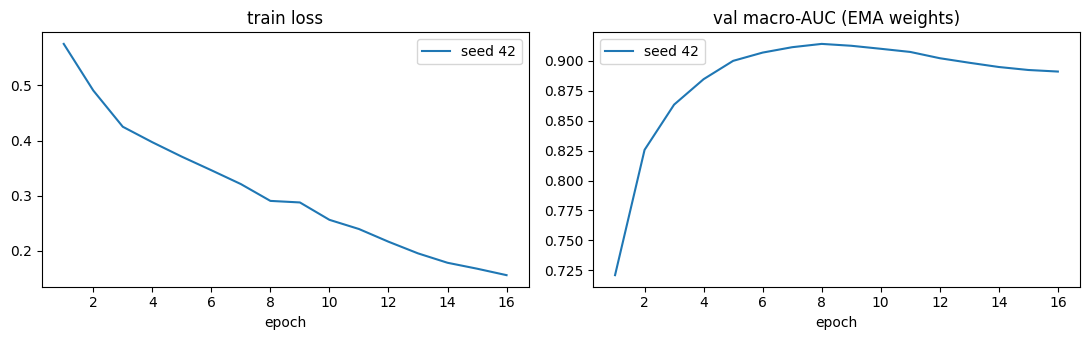

In [10]:
RESULTS = {}
for seed in SEEDS:
    RESULTS[seed] = train_one(seed)
CKPTS = [RESULTS[s][0] for s in SEEDS]
print("\nCheckpoints:", CKPTS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for s in SEEDS:
    h = pd.DataFrame(RESULTS[s][1])
    ax[0].plot(h.epoch, h.train_loss, label=f"seed {s}"); ax[1].plot(h.epoch, h.val_auc, label=f"seed {s}")
ax[0].set_title("train loss"); ax[1].set_title("val macro-AUC (EMA weights)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 9. Final evaluation
Probabilities are averaged over checkpoints (if more than one seed) and 4 flip views. **Thresholds are chosen on the validation set only**, then applied unchanged to the test set.

In [11]:
def load_model(path):
    m = build_model(pretrained=False)
    m.load_state_dict(torch.load(path, map_location=DEVICE)["state_dict"])
    return m.eval()

def ensemble_predict(paths, loader, tta=True):
    Ps = []
    for p in paths:
        m = load_model(p); P, L = predict(m, loader, tta=tta); Ps.append(P); del m
        torch.cuda.empty_cache()
    return np.mean(Ps, 0), L

P_val, L_val   = ensemble_predict(CKPTS, val_loader)
P_test, L_test = ensemble_predict(CKPTS, test_loader)
thr = tune_thresholds(P_val, L_val)                                  # <- tuned on VAL only

rep = report(P_test, L_test, thr)
pred = (P_test > thr).astype(int)
print("TEST set - per class (val-tuned thresholds)")
print(rep.round(3).to_string())
print(f"\nmacro AUC {np.nanmean(rep.AUC):.4f} | mAP {np.nanmean(rep.AP):.4f} | "
      f"macro-F1 {f1_score(L_test, pred, average='macro', zero_division=0):.4f} | "
      f"weighted-F1 {f1_score(L_test, pred, average='weighted', zero_division=0):.4f} | "
      f"micro-F1 {f1_score(L_test, pred, average='micro', zero_division=0):.4f}")
print(f"macro-F1 at fixed 0.5 threshold: {f1_score(L_test, (P_test > 0.5).astype(int), average='macro', zero_division=0):.4f}")

rep.to_csv(os.path.join(OUT_DIR, "test_metrics.csv"))
json.dump(dict(zip(CLASSES, map(float, thr))), open(os.path.join(OUT_DIR, "thresholds.json"), "w"), indent=2)
pd.DataFrame(P_test, columns=CLASSES).assign(filename=df.filename.values[test_idx]).to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"), index=False)

TEST set - per class (val-tuned thresholds)
                  support   thr    AUC     AP  precision  recall     F1
cls                                                                    
N (Normal)            586  0.61  0.869  0.811      0.736   0.870  0.797
D (Diabetes)          327  0.60  0.897  0.809      0.787   0.667  0.722
G (Glaucoma)           54  0.58  0.944  0.481      0.492   0.556  0.522
C (Cataract)           61  0.70  0.994  0.939      0.961   0.803  0.875
A (AMD)                39  0.70  0.964  0.743      0.727   0.615  0.667
H (Hypertension)       32  0.48  0.779  0.076      0.103   0.094  0.098
M (Myopia)             47  0.85  0.998  0.936      0.972   0.745  0.843
O (Other)             125  0.49  0.858  0.576      0.358   0.736  0.482

macro AUC 0.9128 | mAP 0.6713 | macro-F1 0.6258 | weighted-F1 0.7191 | micro-F1 0.7097
macro-F1 at fixed 0.5 threshold: 0.6037


## 10. Interpretability
For one test image, shows: (1) the patches chosen by the global scout, (2) the scout's attention heat-map, (3) Swin Grad-CAM for the explained class, (4) EfficientNet Grad-CAM mapped back onto the full image through the patch boxes.

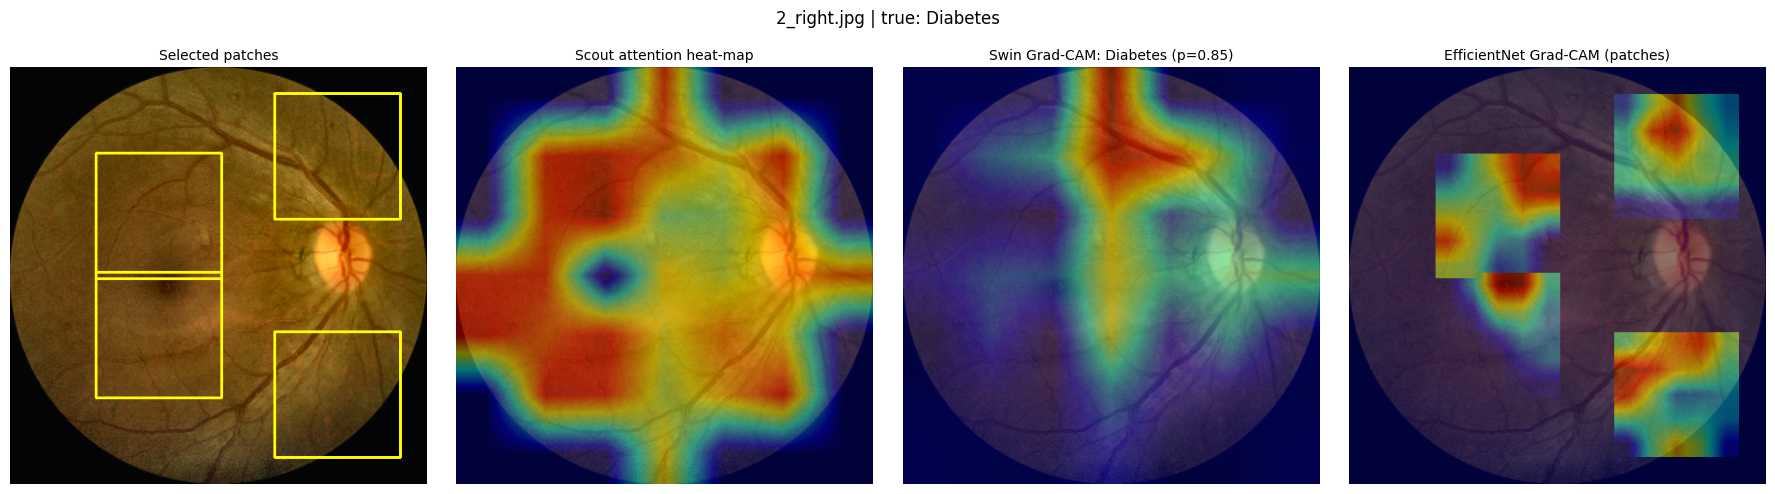

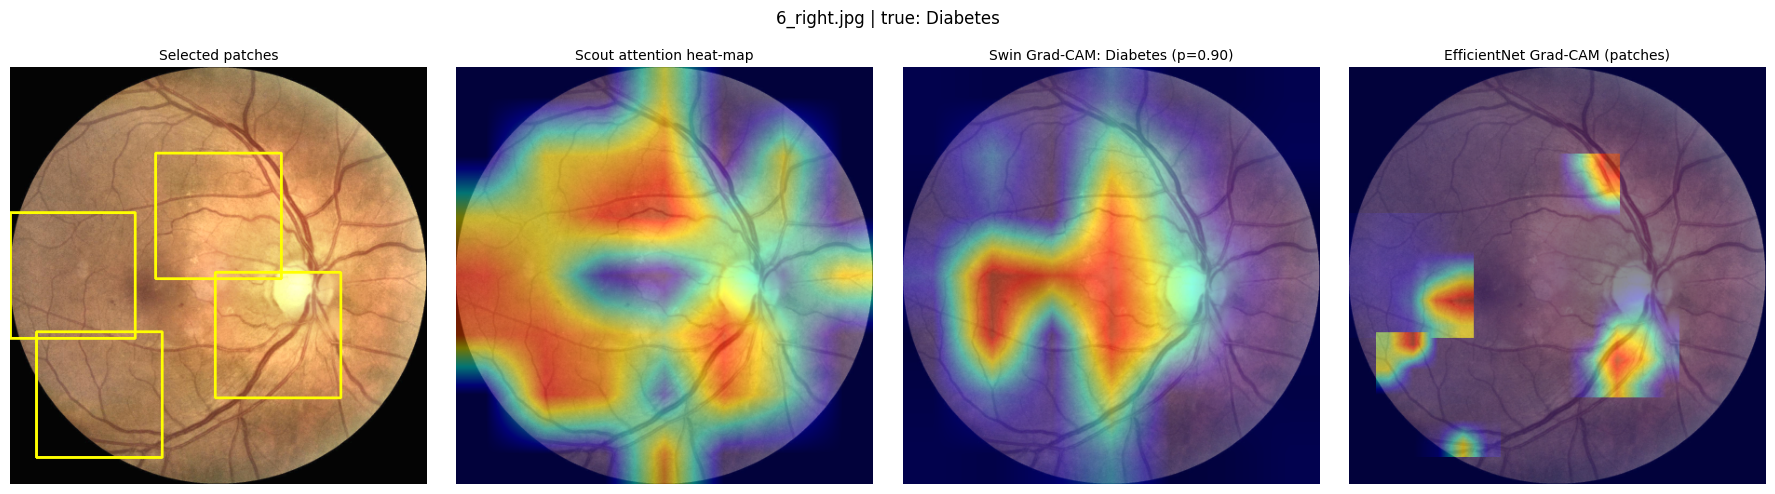

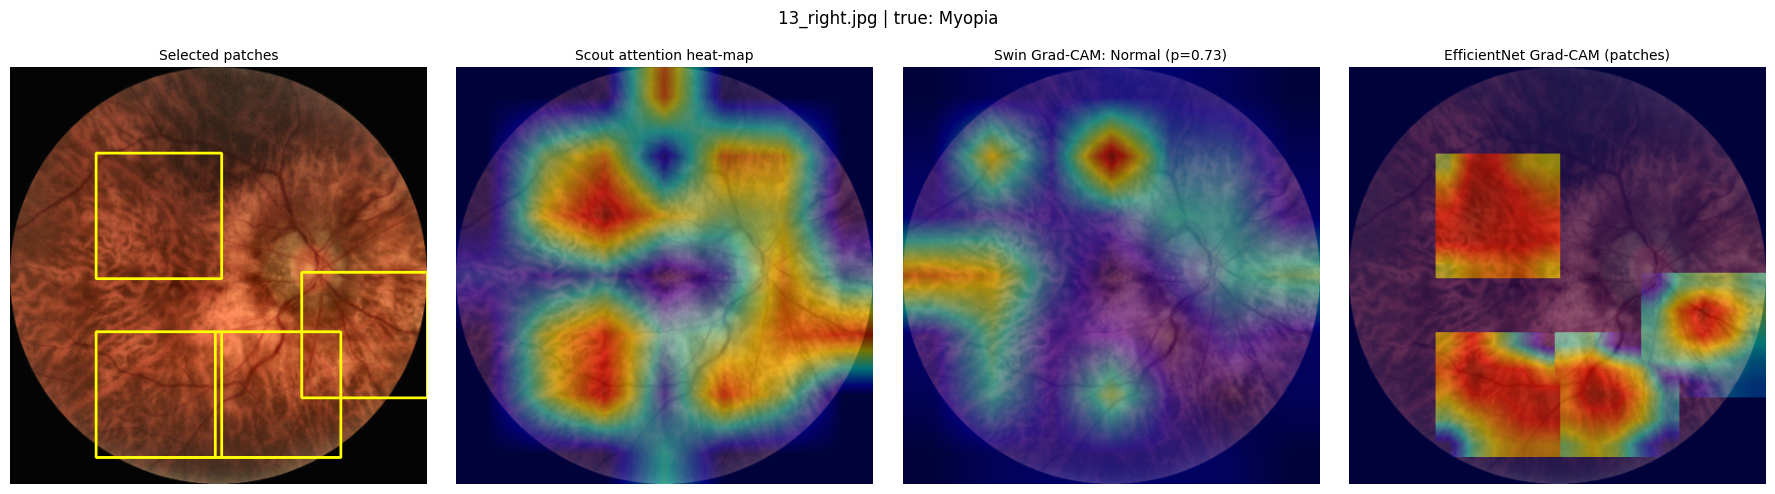

In [12]:
def _to_nchw(t, channels):
    if t.ndim == 3:
        s = int(round(t.shape[1] ** 0.5)); t = t.reshape(t.shape[0], s, s, t.shape[2])
    if t.shape[-1] == channels and t.shape[1] != channels:
        t = t.permute(0, 3, 1, 2)
    return t

def _cam(a, g, channels):
    a, g = _to_nchw(a, channels), _to_nchw(g, channels)
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1))              # N,h,w
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).cpu().numpy()

def explain(model, xb_uint8, target=None):
    # xb_uint8: one cached image, HWC uint8 tensor. Returns image, boxes, heat, global CAM, local CAM, class, prob
    store = {}
    def mk(name):
        def hook(m, i, o):
            store[name + "_a"] = o.detach()
            o.register_hook(lambda gr: store.__setitem__(name + "_g", gr.detach()))
        return hook
    h1 = model.global_extractor.norm.register_forward_hook(mk("g"))
    h2 = model.local_extractor.blocks[-1].register_forward_hook(mk("l"))
    model.eval(); model.zero_grad(set_to_none=True)
    x = prep(xb_uint8[None], False)
    logits, aux, heat, boxes = model(x, return_extra=True)               # fp32 for clean gradients
    probs = torch.sigmoid(logits.detach())[0].cpu().numpy()
    k = int(probs.argmax()) if target is None else target
    logits[0, k].backward()
    h1.remove(); h2.remove()
    S = x.shape[-1]
    g_cam = cv2.resize(_cam(store["g_a"], store["g_g"], model.global_extractor.num_features)[0], (S, S))
    l_maps = _cam(store["l_a"], store["l_g"], store["l_a"].shape[1])
    l_cam = np.zeros((S, S), np.float32)
    for m, (_, x1, y1, x2, y2) in zip(l_maps, boxes.cpu().numpy()):
        x1, y1, x2, y2 = int(round(x1)), int(round(y1)), int(round(x2)), int(round(y2))
        l_cam[y1:y2, x1:x2] = np.maximum(l_cam[y1:y2, x1:x2], cv2.resize(m, (x2 - x1, y2 - y1)))
    h = heat[0].cpu().numpy(); h = (h - h.min()) / (h.max() - h.min() + 1e-8)
    return xb_uint8.numpy(), boxes.cpu().numpy(), cv2.resize(h, (S, S)), g_cam, l_cam, k, float(probs[k])

def overlay(img, cam):
    col = cv2.applyColorMap(np.uint8(255 * np.clip(cam, 0, 1)), cv2.COLORMAP_JET)[..., ::-1]
    return np.uint8(0.55 * img + 0.45 * col)

def show_explanation(model, test_pos, target=None):
    xb, yb = test_loader.dataset[test_pos]
    img, boxes, heat, g_cam, l_cam, k, p = explain(model, xb, target)
    boxed = img.copy()
    for _, x1, y1, x2, y2 in boxes:
        cv2.rectangle(boxed, (int(x1), int(y1)), (int(x2), int(y2)), (255, 255, 0), 2)
    true = [CLASS_NAMES[c] for c, v in zip(CLASSES, yb.numpy()) if v > 0]
    fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
    for a, im, t in zip(ax, [boxed, overlay(img, heat), overlay(img, g_cam), overlay(img, l_cam)],
                        ["Selected patches", "Scout attention heat-map",
                         f"Swin Grad-CAM: {CLASS_NAMES[CLASSES[k]]} (p={p:.2f})", "EfficientNet Grad-CAM (patches)"]):
        a.imshow(im); a.set_title(t, fontsize=10); a.axis("off")
    fig.suptitle(f"{df.filename.values[test_idx][test_pos]} | true: {', '.join(true) or '-'}", y=1.02)
    plt.tight_layout(); plt.show()

explain_model = load_model(CKPTS[0])
# pick a few test images that contain a rarer disease (anything other than only 'Normal')
cand = [i for i in range(len(test_idx)) if Y[test_idx[i]][1:].any()][:3] or [0, 1, 2]
for pos in cand:
    show_explanation(explain_model, pos)